# Exploration du jeu de données : *Escherichia coli* - Ciprofloxacine


In [15]:
import copy
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    precision_recall_curve, confusion_matrix,
)

# on évite les conflist entre les packagese
torch.set_num_threads(1)

# on configure la graine
SEED = 123


## 1. Importation du jeu de données

### 1.1 Importation des données complète

In [2]:
# Définition du chemin relatif 
data_path = Path("../data/processed/ecoli_ciprofloxacin_snp.parquet")
if not data_path.exists():
    data_path = Path("data/processed/ecoli_ciprofloxacin_snp.parquet")

# importation des données
df = pd.read_parquet(data_path)
print(f"Jeu de données chargé : {df.shape[0]:,} lignes et {df.shape[1]:,} colonnes.")


Jeu de données chargé : 5,935 lignes et 20,933 colonnes.


### 1.2 Importation des données splits

In [3]:
# On écrit le chemin du jeu de données
DATA = Path("../data/splits_snp_3way")
if not DATA.exists():
    DATA = Path("data/splits_snp_3way")

# On importe les données splits
X_train = pd.read_parquet(DATA / "X_train.parquet")
y_train = pd.read_parquet(DATA / "y_train.parquet")["y"]
meta_train = pd.read_parquet(DATA / "metadata_train.parquet")

X_val = pd.read_parquet(DATA / "X_val.parquet")
y_val = pd.read_parquet(DATA / "y_val.parquet")["y"]
meta_val = pd.read_parquet(DATA / "metadata_val.parquet")

X_test = pd.read_parquet(DATA / "X_test.parquet")
y_test = pd.read_parquet(DATA / "y_test.parquet")["y"]
meta_test = pd.read_parquet(DATA / "metadata_test.parquet")

# on affiche les tailles des données d'entraînement
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)


(4074, 20929)
(932, 20929)
(929, 20929)


### 1.3 Fonction d'évaluation des modèles

In [4]:
def evaluate(name, model, X, y, threshold = 0.5) : 
    proba = model.predict_proba(X)[:,1]
    pred = (proba >= threshold).astype(int)
    
     # métriques stockées pour le tableau comparatif
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
    }

    print(f"\n=== {name} (seuil = {threshold}) ===")
    print(f"Accuracy          : {accuracy_score(y, pred):.3f}")
    print(f"Balanced accuracy : {balanced_accuracy_score(y, pred):.3f}")
    print(f"Precision         : {precision_score(y, pred, zero_division=0):.3f}")
    print(f"Recall            : {recall_score(y, pred, zero_division=0):.3f}")
    print(f"F1                : {f1_score(y, pred, zero_division=0):.3f}")
    print(f"ROC-AUC           : {roc_auc_score(y, proba):.3f}")
    print(f"PR-AUC            : {average_precision_score(y, proba):.3f}")

    

    print(pd.DataFrame(
        confusion_matrix(y, pred),
        index = ["Observé 0", "Observé 1"],
        columns = ["Prédit 0", "Prédit 1"]
    ))

    return metrics




## 2. Machine learning 

### 2.1 Régression logistique 

In [5]:
# on construit le modèle 
model_lr = LogisticRegression(
    random_state = 42, 
    max_iter = 2000
)

# entraînement du modèle 
model_lr.fit(X_train, y_train)

# évaluation du modèle 
evaluate("Régression logistique — validation", model_lr, X_val, y_val)


=== Régression logistique — validation (seuil = 0.5) ===
Accuracy          : 0.845
Balanced accuracy : 0.633
Precision         : 0.570
Recall            : 0.314
F1                : 0.405
ROC-AUC           : 0.844
PR-AUC            : 0.554
           Prédit 0  Prédit 1
Observé 0       739        37
Observé 1       107        49


{'model': 'Régression logistique — validation',
 'accuracy': 0.8454935622317596,
 'balanced_acc': 0.633211075865715,
 'precision': 0.5697674418604651,
 'recall': 0.3141025641025641,
 'f1': 0.4049586776859504,
 'roc_auc': 0.8435187020882896,
 'pr_auc': 0.5537802741049868}

#### Régression logistique pénalisée L1 (Lasso)

La pénalité L1 force la plupart des coefficients à exactement 0 : seuls les SNP utiles à la prédiction sont conservés. On choisit la force de régularisation `C` (petit `C` = pénalité forte) en maximisant la PR-AUC sur le jeu de validation.

In [ ]:
# grille de valeurs de C (C = 1 / lambda)
C_grid = [0.005, 0.01, 0.05, 0.1, 0.5, 1.0]

lasso_results = []
for C in C_grid:
    m = LogisticRegression(
        penalty = "l1",
        solver = "liblinear",
        C = C,
        random_state = 42,
        max_iter = 2000,
    )
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_val)[:, 1]
    lasso_results.append({
        "C": C,
        "nb_coef_non_nuls": int((m.coef_[0] != 0).sum()),
        "val_pr_auc": average_precision_score(y_val, proba),
        "val_roc_auc": roc_auc_score(y_val, proba),
    })

lasso_results = pd.DataFrame(lasso_results)
print(lasso_results)

# on retient le C qui maximise la PR-AUC de validation
best_C = float(lasso_results.loc[lasso_results["val_pr_auc"].idxmax(), "C"])
print(f"\nC retenu : {best_C}")

In [ ]:
# on construit le modèle final avec le meilleur C
model_lasso = LogisticRegression(
    penalty = "l1",
    solver = "liblinear",
    C = best_C,
    random_state = 42,
    max_iter = 2000,
)

# entraînement du modèle
model_lasso.fit(X_train, y_train)

# évaluation du modèle
evaluate("Lasso — validation", model_lasso, X_val, y_val)

In [ ]:
# coefficients du Lasso : on ne garde que les variables sélectionnées (coef != 0)
coef_lasso = pd.Series(model_lasso.coef_[0], index = X_train.columns)
coef_lasso_nz = coef_lasso[coef_lasso != 0]
print(f"Variables sélectionnées par le Lasso : {len(coef_lasso_nz)} / {len(coef_lasso)}")

# top 15 par |coefficient| (positif = associé à la résistance)
top_lasso = coef_lasso_nz.reindex(coef_lasso_nz.abs().sort_values(ascending = False).index).head(15)

fig, ax = plt.subplots(figsize = (8, 6))
colors = ["firebrick" if v > 0 else "steelblue" for v in top_lasso.values]
ax.barh(top_lasso.index[::-1], top_lasso.values[::-1], color = colors[::-1])
ax.axvline(0, color = "black", lw = 0.8)
ax.set_xlabel("Coefficient (log-odds)")
ax.set_title("Lasso — 15 variables les plus influentes")
plt.tight_layout()
plt.show()

### 2.2 RandomForrest

In [6]:
# on construit le modèle 
model_rf = RandomForestClassifier(
    random_state = 42
)

# entraînement du modèle 
model_rf.fit(X_train, y_train)

# évaluation du modèle 
evaluate("Random Forrest — validation", model_rf, X_val, y_val)


=== Random Forrest — validation (seuil = 0.5) ===
Accuracy          : 0.897
Balanced accuracy : 0.692
Precision         : 1.000
Recall            : 0.385
F1                : 0.556
ROC-AUC           : 0.939
PR-AUC            : 0.803
           Prédit 0  Prédit 1
Observé 0       776         0
Observé 1        96        60


{'model': 'Random Forrest — validation',
 'accuracy': 0.8969957081545065,
 'balanced_acc': 0.6923076923076923,
 'precision': 1.0,
 'recall': 0.38461538461538464,
 'f1': 0.5555555555555556,
 'roc_auc': 0.9394990748083532,
 'pr_auc': 0.8027127343216324}

### 2.3 XGBoost

In [7]:
# on construit le modèle 
model_xgb = XGBClassifier(random_state = 42)

# entraînement du modèle 
model_xgb.fit(X_train, y_train)

# évaluation du modèle 
evaluate("XGBoost — validation", model_xgb, X_val, y_val)


=== XGBoost — validation (seuil = 0.5) ===
Accuracy          : 0.974
Balanced accuracy : 0.951
Precision         : 0.929
Recall            : 0.917
F1                : 0.923
ROC-AUC           : 0.986
PR-AUC            : 0.969
           Prédit 0  Prédit 1
Observé 0       765        11
Observé 1        13       143


{'model': 'XGBoost — validation',
 'accuracy': 0.9742489270386266,
 'balanced_acc': 0.9512457044673539,
 'precision': 0.9285714285714286,
 'recall': 0.9166666666666666,
 'f1': 0.9225806451612903,
 'roc_auc': 0.9857173539518901,
 'pr_auc': 0.9685858094092938}

### 2.4 Comparaison des modèles

In [8]:
rows = []
rows.append(evaluate("LogReg", model_lr, X_val, y_val))
rows.append(evaluate("Lasso",  model_lasso, X_val, y_val))
rows.append(evaluate("RF",     model_rf, X_val, y_val))
rows.append(evaluate("XGB",    model_xgb, X_val, y_val))
comparison = pd.DataFrame(rows).set_index("model")
comparison


=== LogReg (seuil = 0.5) ===
Accuracy          : 0.845
Balanced accuracy : 0.633
Precision         : 0.570
Recall            : 0.314
F1                : 0.405
ROC-AUC           : 0.844
PR-AUC            : 0.554
           Prédit 0  Prédit 1
Observé 0       739        37
Observé 1       107        49

=== RF (seuil = 0.5) ===
Accuracy          : 0.897
Balanced accuracy : 0.692
Precision         : 1.000
Recall            : 0.385
F1                : 0.556
ROC-AUC           : 0.939
PR-AUC            : 0.803
           Prédit 0  Prédit 1
Observé 0       776         0
Observé 1        96        60

=== XGB (seuil = 0.5) ===
Accuracy          : 0.974
Balanced accuracy : 0.951
Precision         : 0.929
Recall            : 0.917
F1                : 0.923
ROC-AUC           : 0.986
PR-AUC            : 0.969
           Prédit 0  Prédit 1
Observé 0       765        11
Observé 1        13       143


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
LogReg,0.845494,0.633211,0.569767,0.314103,0.404959,0.843519,0.553780
RF,0.896996,0.692308,1.000000,0.384615,0.555556,0.939499,0.802713
XGB,0.974249,0.951246,0.928571,0.916667,0.922581,0.985717,0.968586


### 2.5 Choix du seuil

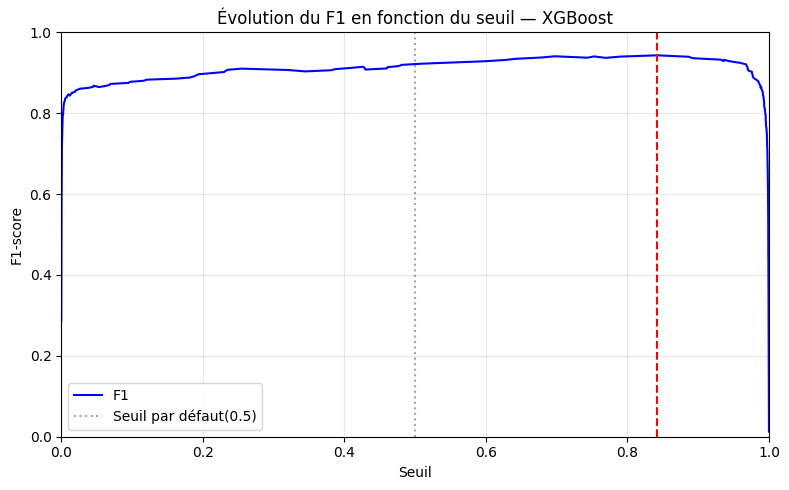

modèle retenu : XGB | seuil F1 max : 0.842


In [9]:
# probabilités  posteriori pour notre Xgboost
proba_val_xgb  = model_xgb.predict_proba(X_val)[:, 1]


# on détermine l'évolution de la précision, du recall en fonction de différent seuil 
prec, rec, thr = precision_recall_curve(y_val, proba_val_xgb)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
f1_plot = f1[:-1]

# on défini le meilleur seuil
best_thr = float(thr[np.argmax(f1[:-1])])

# on affiche la courbe d'évolution de la f1 en fonction du seuil 
fig, ax = plt.subplots(figsize = (8,5))
ax.plot(thr, f1_plot, color = "blue", label = "F1")
ax.axvline(best_thr, color = "red", linestyle = "--")
ax.axvline(0.5, color = "grey", linestyle = ":", alpha = 0.7, label = "Seuil par défaut(0.5)")
ax.set_xlabel("Seuil")
ax.set_ylabel("F1-score")
ax.set_title("Évolution du F1 en fonction du seuil — XGBoost")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# on affiche le meilleur seuil 
print(f"modèle retenu : XGB | seuil F1 max : {best_thr:.3f}")



### 2.6 Courbe de calibration de notre modèle 

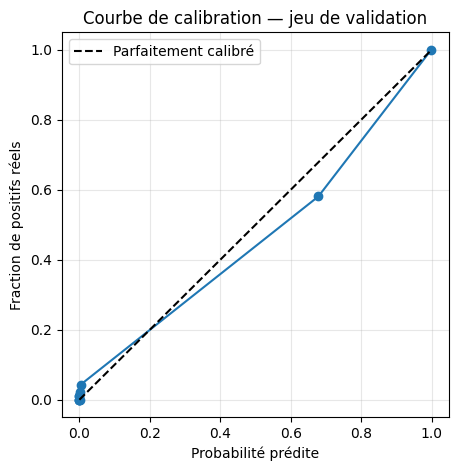

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
prob_true, prob_pred = calibration_curve(y_val, proba_val_xgb, n_bins=10, strategy="quantile")
ax.plot(prob_pred, prob_true, "o-")

ax.plot([0, 1], [0, 1], "k--", label="Parfaitement calibré")
ax.set_xlabel("Probabilité prédite")
ax.set_ylabel("Fraction de positifs réels")
ax.set_title("Courbe de calibration — jeu de validation")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

### 2.8 Test du modèle 

In [11]:
# évaluation du modèle 
evaluate("XGBosst — test", model_xgb, X_test, y_test, best_thr)


=== XGBosst — test (seuil = 0.8421061635017395) ===
Accuracy          : 0.981
Balanced accuracy : 0.952
Precision         : 0.972
Recall            : 0.909
F1                : 0.940
ROC-AUC           : 0.972
PR-AUC            : 0.951
           Prédit 0  Prédit 1
Observé 0       771         4
Observé 1        14       140


{'model': 'XGBosst — test',
 'accuracy': 0.9806243272335845,
 'balanced_acc': 0.9519648093841642,
 'precision': 0.9722222222222222,
 'recall': 0.9090909090909091,
 'f1': 0.9395973154362416,
 'roc_auc': 0.9722832006702976,
 'pr_auc': 0.9511521030015534}

## 3. Interprétabilité

### 3.1 SHAP

Dimensions :  (929, 20929)
Valeur de base :  -1.6098111


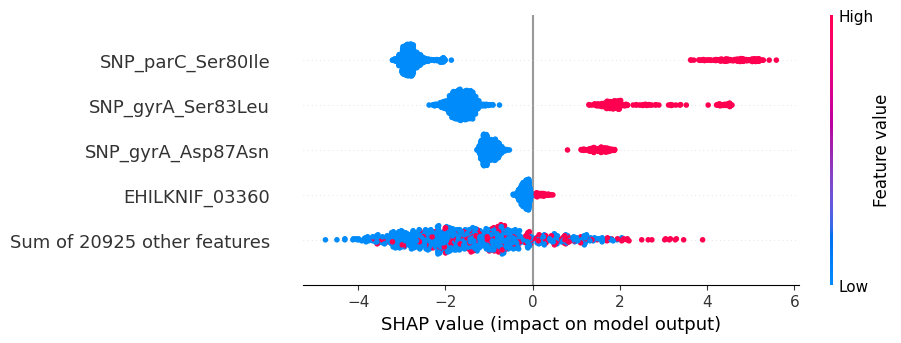

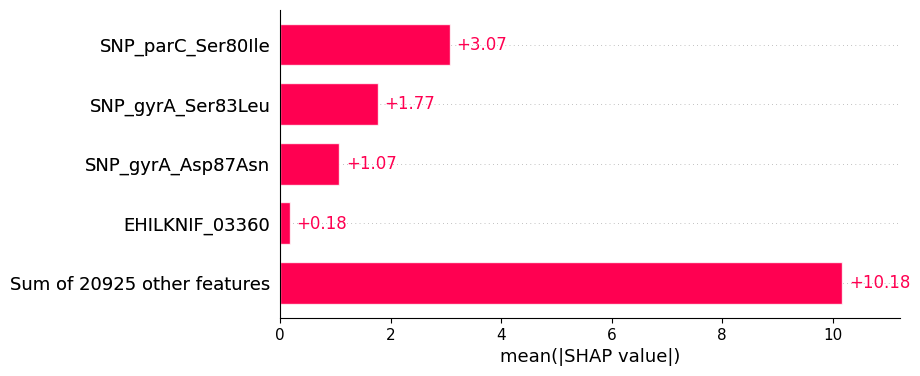

In [ ]:
# on créer l'explainer
explainer_xgb = shap.TreeExplainer(model_xgb)

# on calcul les valeurs de SHAP sur X_test
shap_value_xgb =  explainer_xgb(X_test)
print("Dimensions : ", shap_value_xgb.values.shape)
print("Valeur de base : ", shap_value_xgb.base_values[0])


# vue d'ensemble
shap.plots.beeswarm(shap_value_xgb, max_display = 5)

# classement simple par importance moyenne 
shap.plots.bar(shap_value_xgb, max_display = 5)


#### Comparaison SHAP (XGBoost) vs Lasso (régression logistique)

On compare les variables les plus importantes selon les deux approches : |SHAP| moyen sur le test pour XGBoost, |coefficient| pour le Lasso. Les deux mesures n'ont pas la même échelle, on compare donc les **rangs** et le recouvrement des top-k.

In [ ]:
from scipy.stats import spearmanr

# importance SHAP : moyenne des |SHAP| sur le test
imp_shap = pd.Series(np.abs(shap_value_xgb.values).mean(axis = 0), index = X_test.columns)

# importance Lasso : |coefficient|
imp_lasso = coef_lasso.abs()

# recouvrement des top-k
for k in [5, 10, 20, 50]:
    top_s = set(imp_shap.nlargest(k).index)
    top_l = set(imp_lasso.nlargest(k).index)
    inter = top_s & top_l
    print(f"top {k:>2} : {len(inter):>2} variables communes (Jaccard = {len(inter) / len(top_s | top_l):.2f})")

# corrélation de Spearman sur l'union des variables utilisées par au moins un des deux modèles
used = imp_shap.index[(imp_shap > 0) | (imp_lasso > 0)]
rho, pval = spearmanr(imp_shap[used], imp_lasso[used])
print(f"\nSpearman sur {len(used)} variables utilisées : rho = {rho:.3f} (p = {pval:.1e})")

# tableau côte à côte du top 20 SHAP
top20 = imp_shap.nlargest(20).index
rang_lasso = imp_lasso.rank(ascending = False, method = "min")
comparaison_imp = pd.DataFrame({
    "SHAP_moyen": imp_shap[top20],
    "rang_SHAP": range(1, 21),
    "coef_lasso": coef_lasso[top20],
    "rang_lasso": rang_lasso[top20].astype(int),
    "sélectionné_lasso": coef_lasso[top20] != 0,
})
comparaison_imp

### 3.2 Analyse d'erreurs

Nombre de Faux Positifs : 4
Nombre de Faux Négatifs : 14

=== Analyse d'un Faux Positif (Prédit Résistant, en réalité Sensible) ===


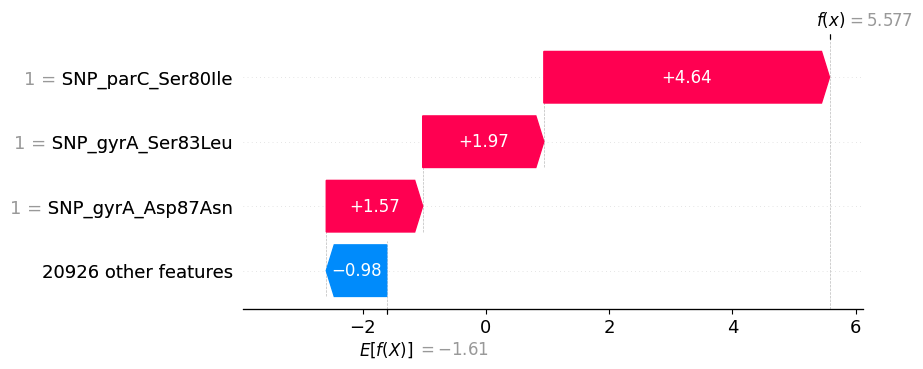


=== Analyse d'un Faux Négatif (Prédit Sensible, en réalité Résistant) ===


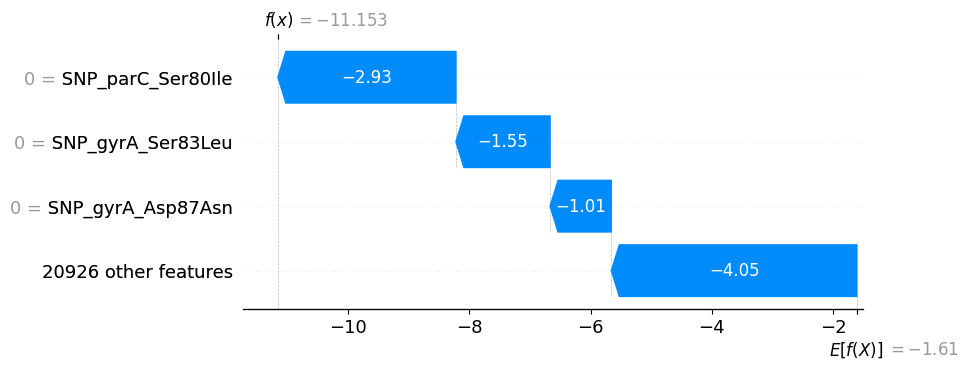

In [40]:
# on réccupère les prédictions sur le test 
proba_test = model_xgb.predict_proba(X_test)[:,1]
pred_test = (proba_test >= best_thr)
y_true = y_test.values

# on cherche les faux positifs
i_fp = np.where((y_true == 0) & (pred_test == 1))[0]

# on chercher les faux négatifs
i_fn = np.where((y_true == 1) & (pred_test == 0))[0]

# on regarde la taille des deux df
print(f"Nombre de Faux Positifs : {len(i_fp)}")
print(f"Nombre de Faux Négatifs : {len(i_fn)}")

# on affoche la waterfall pour le premier fn
if len(i_fp) > 0:
    print("\n=== Analyse d'un Faux Positif (Prédit Résistant, en réalité Sensible) ===")
    shap.plots.waterfall(shap_value_xgb[i_fp[0]], max_display=4)

if len(i_fn) > 0:
    print("\n=== Analyse d'un Faux Négatif (Prédit Sensible, en réalité Résistant) ===")
    shap.plots.waterfall(shap_value_xgb[i_fn[0]], max_display=4)

## 4. Deep learning sans sélection de variable 

### 3.1 Tenseur 

In [ ]:
# on transforme nos données en tenseurs
Xtrain = torch.tensor(X_train.to_numpy(dtype=np.float32))
Xval   = torch.tensor(X_val.to_numpy(dtype=np.float32))
Xtest  = torch.tensor(X_test.to_numpy(dtype=np.float32))
ytrain = torch.tensor(y_train.to_numpy(dtype=np.float32)).view(-1, 1)
y_val_train = torch.tensor(y_val.to_numpy(dtype=np.float32))


# on défini la notre DataLoader
train_loader = DataLoader(
    TensorDataset(Xtrain, ytrain),
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

# on affiche la taille des données d'entraînement
print(Xtrain.shape, ytrain.shape)


torch.Size([4074, 20929]) torch.Size([4074, 1])


### 3.2  Configuration du modèle de classification

In [ ]:
# pondération pour le déséqulibre des classes 
nb_pos = (y_train == 1).sum()
nb_neg = (y_train == 0).sum()
pos_weight = torch.tensor(([nb_neg/nb_pos]), dtype=torch.float32)
print(f"pos_weight = {pos_weight.item()}")

# on construit l'architecture avec deux couches cachées
mlp = nn.Sequential(
    nn.Linear(Xtrain.shape[1], 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)

# défintion du critère de cross entropie
criterion_eval = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# descente de gradient 
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay = 1e-4)


pos_weight = 3.1784615516662598


### 3.3 Entraînement

In [ ]:
# on initialise l'historique prenant en compte l'évolution des loss
history = {
    "train_loss": [], 
    "val_loss": [],
    "train_pr_auc": [], 
    "val_pr_auc": [],
}
best_pr, patience, best_state = -1.0, 15, None
best_epoch = 0



for epoch in range(200):
    # entraînement 
    mlp.train()
    total = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion_eval(mlp(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)

    # validation 
    mlp.eval()
    with torch.no_grad():
        logits_train = mlp(Xtrain).squeeze(1)
        logits_val = mlp(Xval).squeeze(1)
        proba_train = torch.sigmoid(logits_train).cpu().numpy()
        proba_val = torch.sigmoid(logits_val).cpu().numpy()
        loss_train = criterion_eval(logits_train, ytrain.squeeze(1)).item()
        loss_val = criterion_eval(logits_val, y_val_train).item()

    history["train_loss"].append(loss_train)
    history["val_loss"].append(loss_val)
    history["train_pr_auc"].append(average_precision_score(y_train, proba_train))
    history["val_pr_auc"].append(average_precision_score(y_val, proba_val))



    # on stoppe de manière prématurée sur le PR-AUC de validation 
    if history["val_pr_auc"][-1] > best_pr:
        best_pr = history["val_pr_auc"][-1]
        best_epoch = epoch
        patience = 15
        best_state = copy.deepcopy(mlp.state_dict())
    else:
        patience -= 1
        if patience == 0:
            print(f"Early stopping epoch {epoch} — best val PR-AUC {best_pr:.3f}")
            break

mlp.load_state_dict(best_state)
print(f"meilleur epoch = {best_epoch} | best val PR-AUC = {best_pr:.3f}")

Early stopping epoch 15 — best val PR-AUC 0.685
meilleur epoch = 0 | best val PR-AUC = 0.685


### 3.4 Visusalisation des loss en fonction des epoch 

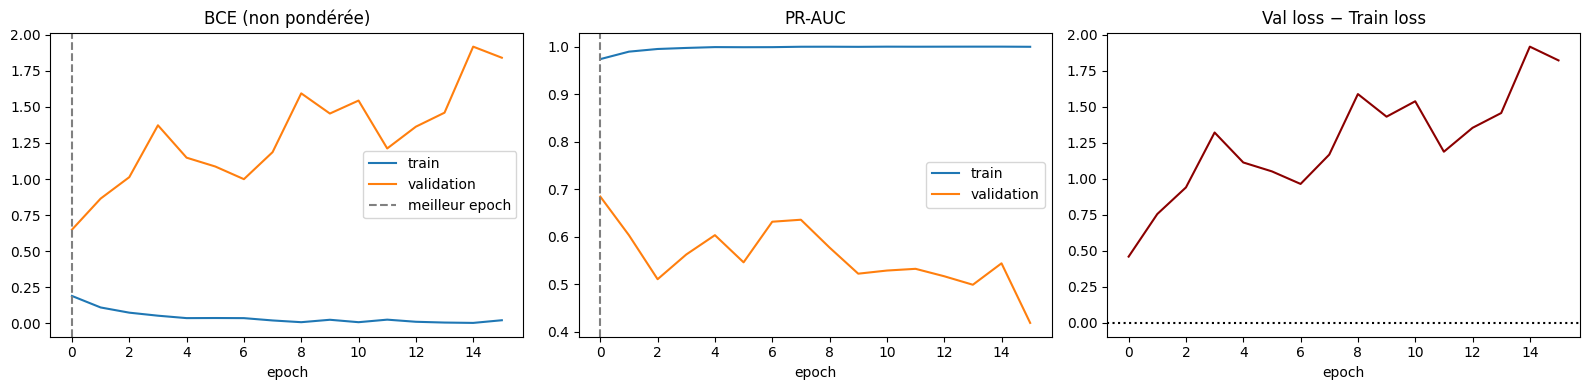

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Loss train vs validation
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].axvline(best_epoch, ls="--", color="grey", label="meilleur epoch")
axes[0].set_title("BCE (non pondérée)")
axes[0].set_xlabel("epoch")
axes[0].legend()

# 2. PR-AUC train vs validation
axes[1].plot(history["train_pr_auc"], label="train")
axes[1].plot(history["val_pr_auc"], label="validation")
axes[1].axvline(best_epoch, ls="--", color="grey")
axes[1].set_title("PR-AUC")
axes[1].set_xlabel("epoch")
axes[1].legend()

# 3. Écart de généralisation
gap = np.array(history["val_loss"]) - np.array(history["train_loss"])
axes[2].plot(gap, color="darkred")
axes[2].set_title("Val loss − Train loss")
axes[2].set_xlabel("epoch")
axes[2].axhline(0, ls=":", color="black")

plt.tight_layout()
plt.show()

### 3.5 Évaluation

In [ ]:
# On défini une classe TorchProba afin de facilité l'évaluation de notre MLP
class TorchProba:
    def __init__(self, net):
        self.net = net

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            xb = torch.tensor(np.asarray(X, dtype=np.float32))
            p = torch.sigmoid(self.net(xb)).cpu().numpy().ravel()
        return np.column_stack([1 - p, p])


mlp_eval = TorchProba(mlp)

# validation
res_val = evaluate("MLP — validation", mlp_eval, X_val, y_val)

# seuil choisi sur la validation
proba_val = mlp_eval.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, proba_val)
f1_curve = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
best_thr = float(thr[np.argmax(f1_curve[:-1])])
print(f"seuil optimal (F1 validation) : {best_thr:.3f}")

# test
res_test = evaluate("MLP — TEST", mlp_eval, X_test, y_test, threshold=best_thr)



=== MLP — validation (seuil = 0.5) ===
Accuracy          : 0.770
Balanced accuracy : 0.780
Precision         : 0.405
Recall            : 0.795
F1                : 0.537
ROC-AUC           : 0.860
PR-AUC            : 0.685
           Prédit 0  Prédit 1
Observé 0       594       182
Observé 1        32       124
seuil optimal (F1 validation) : 0.776

=== MLP — TEST (seuil = 0.7758451104164124) ===
Accuracy          : 0.899
Balanced accuracy : 0.825
Precision         : 0.688
Recall            : 0.714
F1                : 0.701
ROC-AUC           : 0.882
PR-AUC            : 0.730
           Prédit 0  Prédit 1
Observé 0       725        50
Observé 1        44       110


## 5. Deep learning avec sélection de variables

### 5.1 On détermine les meilleurs variables à utiliser

In [52]:
# on crée un jeu de données avce des variables sélectionnée de SHAP sur le train 
explainer_train = shap.TreeExplainer(model_xgb)

# on détermine les valueurs de shap pour ce jeu de données
shap_value_train = explainer_train(X_train.sample(1000, random_state = 42))

# on cacul l'importance moyenne 
mean_abs_shap = np.abs(shap_value_train.values).mean(axis=0)
top_50_indices = np.argsort(mean_abs_shap)[-50:]
top_50_features = X_train.columns[top_50_indices]

### 5.2 On filtre tous les jeu de données

In [57]:
#  on applique le filtre sur train, validation et test
X_train_top = torch.tensor(X_train[top_50_features].values, dtype=torch.float32)
X_val_top = torch.tensor(X_val[top_50_features].values, dtype=torch.float32)
X_test_top = torch.tensor(X_test[top_50_features].values, dtype=torch.float32)

# on recréer le data loader 
train_loader_top = DataLoader(
    TensorDataset(X_train_top, ytrain),
    batch_size = 64,
    shuffle = True
)

# on affiche la taille des données d'entraînement
print(X_train_top.shape, ytrain.shape)


torch.Size([4074, 50]) torch.Size([4074, 1])


### 3.2  Configuration du modèle de classification

In [ ]:
# pondération pour le déséqulibre des classes 
nb_pos = (y_train == 1).sum()
nb_neg = (y_train == 0).sum()
pos_weight = torch.tensor(([nb_neg/nb_pos]), dtype=torch.float32)
print(f"pos_weight = {pos_weight.item()}")

# on construit l'architecture avec deux couches cachées
mlp = nn.Sequential(
    nn.Linear(50, 64),
    nn.ReLU(),  
    nn.Dropout(0.5),
    nn.Linear(64, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

# défintion du critère de cross entropie
criterion_eval = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# descente de gradient 
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay = 1e-4)


pos_weight = 3.1784615516662598


### 3.3 Entraînement

In [70]:
# on initialise l'historique prenant en compte l'évolution des loss
history = {
    "train_loss": [], 
    "val_loss": [],
    "train_pr_auc": [], 
    "val_pr_auc": [],
}
best_pr, patience, best_state = -1.0, 15, None
best_epoch = 0

for epoch in range(200):
    # entraînement 
    mlp.train()
    total = 0.0
    # train_loader_top charge les données filtrées (50 features)
    for xb, yb in train_loader_top:
        optimizer.zero_grad()
        loss = criterion_eval(mlp(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)

    # validation 
    mlp.eval()
    with torch.no_grad():
        logits_train = mlp(X_train_top).squeeze(1)
        logits_val = mlp(X_val_top).squeeze(1)
        
        proba_train = torch.sigmoid(logits_train).cpu().numpy()
        proba_val = torch.sigmoid(logits_val).cpu().numpy()
        
        loss_train = criterion_eval(logits_train, ytrain.squeeze(1)).item()
        loss_val = criterion_eval(logits_val, y_val_train).item()

    history["train_loss"].append(loss_train)
    history["val_loss"].append(loss_val)
    history["train_pr_auc"].append(average_precision_score(y_train, proba_train))
    history["val_pr_auc"].append(average_precision_score(y_val, proba_val))


    # on stoppe de manière prématurée sur le PR-AUC de validation 
    if history["val_pr_auc"][-1] > best_pr:
        best_pr = history["val_pr_auc"][-1]
        best_epoch = epoch
        patience = 15
        best_state = copy.deepcopy(mlp.state_dict())
    else:
        patience -= 1
        if patience == 0:
            print(f"Early stopping epoch {epoch} — best val PR-AUC {best_pr:.3f}")
            break

mlp.load_state_dict(best_state)
print(f"meilleur epoch = {best_epoch} | best val PR-AUC = {best_pr:.3f}")

Early stopping epoch 32 — best val PR-AUC 0.964
meilleur epoch = 17 | best val PR-AUC = 0.964


### 3.4 Visusalisation des loss en fonction des epoch 

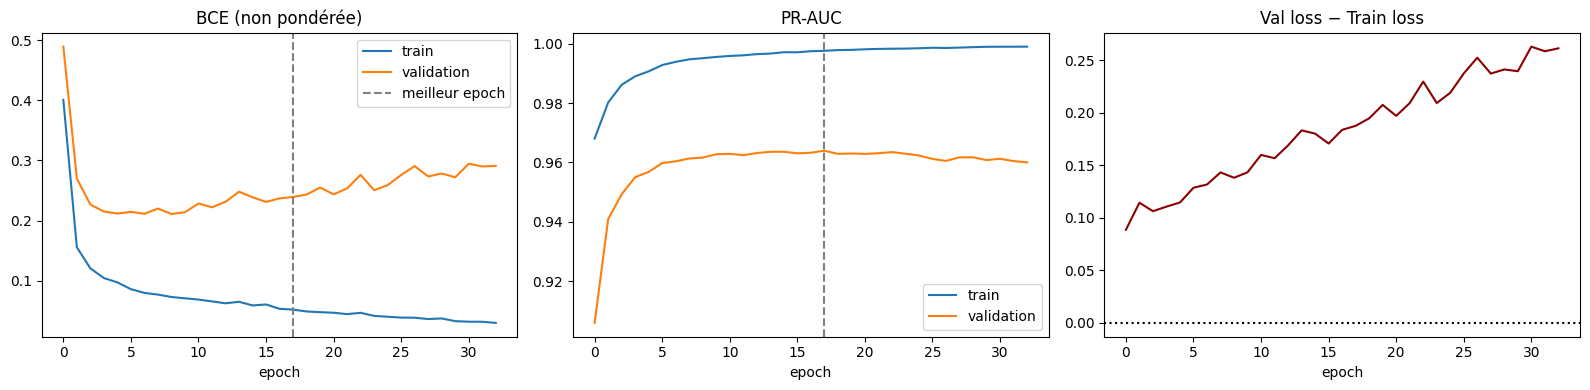

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Loss train vs validation
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].axvline(best_epoch, ls="--", color="grey", label="meilleur epoch")
axes[0].set_title("BCE (non pondérée)")
axes[0].set_xlabel("epoch")
axes[0].legend()

# 2. PR-AUC train vs validation
axes[1].plot(history["train_pr_auc"], label="train")
axes[1].plot(history["val_pr_auc"], label="validation")
axes[1].axvline(best_epoch, ls="--", color="grey")
axes[1].set_title("PR-AUC")
axes[1].set_xlabel("epoch")
axes[1].legend()

# 3. Écart de généralisation
gap = np.array(history["val_loss"]) - np.array(history["train_loss"])
axes[2].plot(gap, color="darkred")
axes[2].set_title("Val loss − Train loss")
axes[2].set_xlabel("epoch")
axes[2].axhline(0, ls=":", color="black")

plt.tight_layout()
plt.show()

### 3.5 Évaluation

In [73]:
# On défini une classe TorchProba afin de facilité l'évaluation de notre MLP
class TorchProba:
    def __init__(self, net):
        self.net = net

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            xb = torch.tensor(np.asarray(X, dtype=np.float32))
            p = torch.sigmoid(self.net(xb)).cpu().numpy().ravel()
        return np.column_stack([1 - p, p])


mlp_eval = TorchProba(mlp)

# validation
res_val = evaluate("MLP — validation", mlp_eval, X_val_top, y_val)

# seuil choisi sur la validation
proba_val = mlp_eval.predict_proba(X_val_top)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, proba_val)
f1_curve = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
best_thr = float(thr[np.argmax(f1_curve[:-1])])
print(f"seuil optimal (F1 validation) : {best_thr:.3f}")

# test
res_test = evaluate("MLP — TEST", mlp_eval, X_test_top, y_test, threshold=best_thr)



=== MLP — validation (seuil = 0.5) ===
Accuracy          : 0.967
Balanced accuracy : 0.947
Precision         : 0.888
Recall            : 0.917
F1                : 0.902
ROC-AUC           : 0.985
PR-AUC            : 0.964
           Prédit 0  Prédit 1
Observé 0       758        18
Observé 1        13       143
seuil optimal (F1 validation) : 0.960

=== MLP — TEST (seuil = 0.9604736566543579) ===
Accuracy          : 0.982
Balanced accuracy : 0.953
Precision         : 0.979
Recall            : 0.909
F1                : 0.943
ROC-AUC           : 0.970
PR-AUC            : 0.954
           Prédit 0  Prédit 1
Observé 0       772         3
Observé 1        14       140
